<a href="https://colab.research.google.com/github/widyy123/gis-career-spatial-data-automation/blob/main/Untitled11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1. SAMPEL DATASET OTOMATISASI ASET SPASIAL ===
   Dist_to_Center (km)  Buffer_Zone (m)  Density_Score  Access_Rating  \
0             2.748357       493.086785      86.476885       9.718424   
1             2.382923       488.293152      95.792128       9.113948   
2             2.265263       527.128002      75.365823       8.127416   
3             2.620981       404.335988      62.750822       8.050170   
4             1.993584       515.712367      70.919759       7.370157   

   Asset_Status  
0  Low Priority  
1  Low Priority  
2  Low Priority  
3  Low Priority  
4  Low Priority  

Akurasi Otomatisasi Analisis Spasial: 100.00%

=== LAPORAN EVALUASI ANALISIS SPASIAL ===
                           precision    recall  f1-score   support

             Low Priority       1.00      1.00      1.00        40
High Priority (Blankspot)       1.00      1.00      1.00        40
       Maintenance Needed       1.00      1.00      1.00        40

                 accuracy                 

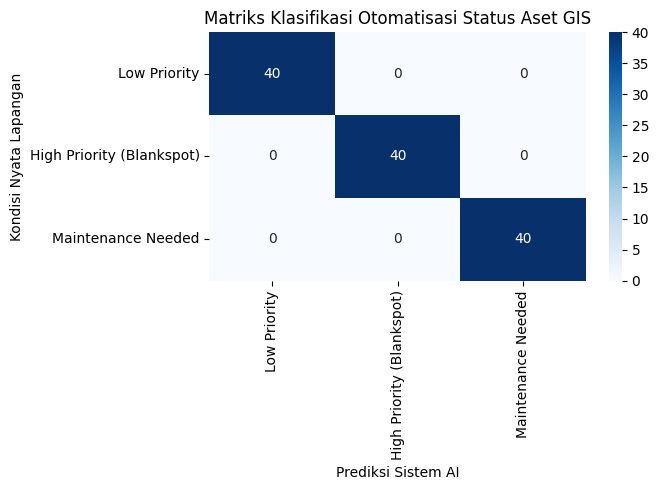

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# STEP 1: SIMULASI DATASET LOKASI & ATRIBUT SPASIAL PERUSAHAAN
# Kebutuhan Industri: Mengolah atribut spasial secara terintegrasi (Python & SQL)
np.random.seed(42)
n_samples = 200

# Fitur Spasial:
# 1. Dist_to_Center : Jarak Aset ke Pusat Kota (km)
# 2. Buffer_Zone    : Radius Cakupan Layanan (meter)
# 3. Density_Score  : Kepadatan Populasi Sekitar Titik
# 4. Access_Rating  : Aksesibilitas Jalan (Skala 1 - 10)

# Kategori Status Layanan Aset:
# 0 = Low Priority (Cakupan Cukup)
# 1 = High Priority (Butuh Tambahan Aset / Blankspot)
# 2 = Maintenance Needed (Aset Perlu Perbaikan)

low_prio = np.random.normal(loc=[2.5, 500, 80, 8.5], scale=[0.5, 50, 10, 0.8], size=(n_samples, 4))
high_prio = np.random.normal(loc=[12.0, 150, 25, 3.0], scale=[2.0, 30, 8, 1.0], size=(n_samples, 4))
maint_prio = np.random.normal(loc=[6.0, 300, 50, 5.0], scale=[1.5, 40, 12, 1.2], size=(n_samples, 4))

X = np.vstack((low_prio, high_prio, maint_prio))
y = np.array([0]*n_samples + [1]*n_samples + [2]*n_samples)

class_names = ['Low Priority', 'High Priority (Blankspot)', 'Maintenance Needed']
feature_names = ['Dist_to_Center (km)', 'Buffer_Zone (m)', 'Density_Score', 'Access_Rating']

df = pd.DataFrame(X, columns=feature_names)
df['Asset_Status'] = [class_names[i] for i in y]

print("=== 1. SAMPEL DATASET OTOMATISASI ASET SPASIAL ===")
print(df.head())


# STEP 2: PREPROCESSING & DATA SPLIT

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# STEP 3: TRAINING MODEL AI UNTUK KLASIFIKASI KEBUTUHAN ASET

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)


# STEP 4: EVALUASI PERFORMA MODEL AUTOMATION

y_pred = mlp.predict(X_test_scaled)

print(f"\nAkurasi Otomatisasi Analisis Spasial: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("=== LAPORAN EVALUASI ANALISIS SPASIAL ===")
print(classification_report(y_test, y_pred, target_names=class_names))


# STEP 5: VISUALISASI CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriks Klasifikasi Otomatisasi Status Aset GIS')
plt.xlabel('Prediksi Sistem AI')
plt.ylabel('Kondisi Nyata Lapangan')
plt.tight_layout()
plt.show()